<a href="https://colab.research.google.com/github/aleksandrawybieralska/climate_policy_Yale/blob/main/scripts/1_data_cleaning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data cleaning script

In [1]:
from google.colab import drive

## Starting to do data cleaning in R

In [39]:
setwd("/content/drive/MyDrive/climate_policy_Yale")
getwd()
# install and load libraries
library(readr)
library(dplyr)
library(tidyr)
library(readxl)
library(writexl)
library(ggplot2)
library(scales)

[1] "/content/drive/MyDrive/climate_policy_Yale"

In [6]:
# read in raw data

emissions_total_raw <- read_xls("raw_data/FAOSTAT_data_en_11-19-2026.xls")


In [7]:
emissions_total_raw

Domain Code,Domain,Area Code (M49),Area,Element Code,Element,Item Code,Item,Year Code,Year,Source Code,Source,Unit,Value,Flag,Flag Description,Note
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<lgl>
GT,Emissions totals,004,Afghanistan,7234,Direct emissions (N2O),5064,Crop Residues,2024,2024,3050,FAO TIER 1,kt,1.3251,E,Estimated value,NA
GT,Emissions totals,004,Afghanistan,7236,Indirect emissions (N2O),5064,Crop Residues,2024,2024,3050,FAO TIER 1,kt,0.2981,E,Estimated value,NA
GT,Emissions totals,004,Afghanistan,7230,Emissions (N2O),5064,Crop Residues,2024,2024,3050,FAO TIER 1,kt,1.6232,E,Estimated value,NA
GT,Emissions totals,004,Afghanistan,724313,Emissions (CO2eq) from N2O (AR5),5064,Crop Residues,2024,2024,3050,FAO TIER 1,kt,430.1480,E,Estimated value,NA
GT,Emissions totals,004,Afghanistan,723113,Emissions (CO2eq) (AR5),5064,Crop Residues,2024,2024,3050,FAO TIER 1,kt,430.1480,E,Estimated value,NA
GT,Emissions totals,004,Afghanistan,7225,Emissions (CH4),5060,Rice Cultivation,2024,2024,3050,FAO TIER 1,kt,18.0880,E,Estimated value,NA
GT,Emissions totals,004,Afghanistan,724413,Emissions (CO2eq) from CH4 (AR5),5060,Rice Cultivation,2024,2024,3050,FAO TIER 1,kt,506.4640,E,Estimated value,NA
GT,Emissions totals,004,Afghanistan,723113,Emissions (CO2eq) (AR5),5060,Rice Cultivation,2024,2024,3050,FAO TIER 1,kt,506.4640,E,Estimated value,NA
GT,Emissions totals,004,Afghanistan,7225,Emissions (CH4),5066,Burning - Crop residues,2024,2024,3050,FAO TIER 1,kt,3.0438,E,Estimated value,NA


## Data cleaning
### Keep CO2-eq values only and delete overapping values

In [20]:
emissions_co2eq <- emissions_total_raw %>%
  filter(
    Element == "Emissions (CO2eq) (AR5)",
    !Item %in% c(
      "Drained organic soils (CO2)",
      "Drained organic soils (N2O)"
    )
  )

Check

In [26]:
emissions_co2eq %>%
  filter(Item %in% c("Other sectors", "Energy", "IPPU", "Waste", "Other")) %>%
  group_by(Item) %>%
  summarise(total = sum(Value)/1e6)

global_total <- sum(emissions_co2eq$Value) / 1e6

other_sectors <- emissions_co2eq %>%
  filter(Item %in% c("Energy", "IPPU", "Waste", "Other")) %>%
  summarise(Gt = sum(Value)/1e6)

global_total
other_sectors


Item,total
<chr>,<dbl>
Energy,53.3967431
IPPU,6.1587393
Other,0.2669931
Waste,2.0550947


[1] 75.79986

Gt
<dbl>
61.87757


## Simple check - get global emissions

### Sum by country

In [21]:
country_emissions <- emissions_co2eq %>%
  filter(Year == 2024) %>%
  group_by(Area) %>%
  summarise(
    emissions_kt_co2eq = sum(Value, na.rm = TRUE)
  ) %>%
  ungroup()

Check

In [22]:
country_emissions %>%
  arrange(desc(emissions_kt_co2eq)) %>%
  head(20)

Area,emissions_kt_co2eq
<chr>,<dbl>
China,16306598.0
"China, mainland",15912575.9
United States of America,6081515.9
India,5318616.4
Brazil,2654662.7
Indonesia,1887281.2
Russian Federation,1457906.4
Iran (Islamic Republic of),1351247.1
Japan,1165312.8


### Calculate global

In [23]:
global_emissions <- country_emissions %>%
  summarise(
    global_kt_co2eq = sum(emissions_kt_co2eq, na.rm = TRUE)
  )

global_emissions

global_kt_co2eq
<dbl>
75799864


### Convert to Gt

In [24]:
global_gt_co2eq <- global_emissions$global_kt_co2eq / 1e6

global_gt_co2eq

[1] 75.79986

# Calculate agrifood systems (AFS) sum

In [28]:
afs_gt_co2eq <- emissions_co2eq %>%
  filter(
    !Item %in% c(
      "Energy",
      "IPPU",
      "Waste",
      "Other"
    )
  ) %>%
  summarise(sum(Value, na.rm = TRUE) / 1e6) %>%
  pull()

afs_gt_co2eq

[1] 13.92229

## Simple figure to demonstrate AFS share to total GHG emissions

### Prep

In [29]:
plot_data <- tibble(
  Category = c("AFS", "Other sectors"),
  Emissions = c(
    afs_gt_co2eq,
    global_gt_co2eq - afs_gt_co2eq
  )
) %>%
  mutate(
    Share = Emissions / sum(Emissions)
  )

### Figure

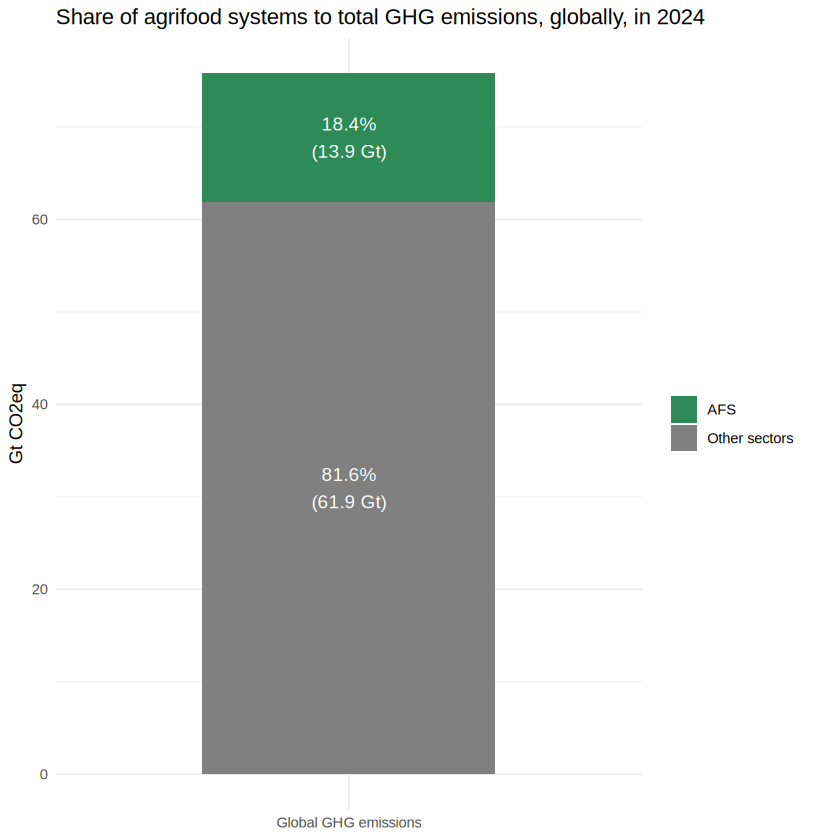

In [33]:
p <- ggplot(plot_data,
            aes(x = "Global GHG emissions",
                y = Emissions,
                fill = Category)) +
  geom_col(width = 0.6) +
  geom_text(
    aes(label = paste0(
      round(Share * 100, 1), "%\n(",
      round(Emissions, 1), " Gt)"
    )),
    position = position_stack(vjust = 0.5),
    color = "white",
    size = 4
  ) +
  labs(
    x = NULL,
    y = "Gt CO2eq",
    title = "Share of agrifood systems to total GHG emissions, globally, in 2024"
  ) +
  scale_fill_manual(
    values = c(
      "AFS" = "#2E8B57",
      "Other sectors" = "#808080"
    )
  ) +
  theme_minimal() +
  theme(
    legend.title = element_blank()
  )

ggsave(
  filename = "figures/global_emissions_afs_share.png",
  plot = p,
  width = 6,
  height = 5,
  dpi = 300
)

p

# Write database

In [41]:
write_xlsx(country_emissions, "clean_data/country_emissions_clean.xlsx")